# Choosing an ETF

## Intro

How should I invest the savings ear-marked for retirement, my RRSP? There is lots of financial advice out there on the relative merits of ETFs (exchange traded funds) and mutual funds, but how to actually select one (or several) funds from the thousands available? In this notebook, I will give some insight into this question by looking at a few metrics, to get an initial understanding of the ETF and mutual fund landscape.

First, a caveat: I am a geoscience professional, not a financial advisor. This Jupyter notebook is my own investigation into the world of investing, while teaching myself python and pandas along the way. There is a lot more that should go into deciding where to invest your money; this notebook is only one piece of the puzzle.

## Assumptions

Let's assume I plan to retire in 24 years, in 2050. That's a long time compared to the ups and downs of the market, so I want to select an investment that will provide the highest growth. For this reason, I will confine my attention to funds that hold 100% stocks, as opposed to more conservative asset allocations like 80% stocks and 20% bonds.

Another assumption is that portfolio managers are not able to outperform the market on such a long time-scale, and that an index fund would do just as well as an actively managed fund. This suggests that paying for advice via high management fees and expenses is not beneficial, and the MER (management expense ratio) should be low.

Finally, I assume that global diversification is desirable, and a good hedge against economic downturns in any one geographic region. (Note however that this caution is somewhat contradictory to the aggressive 100% equity approach.) Nevertheless, since I am Canadian, I impose a values-based over-representation of Canadian investments.

It would be good to empirically test the above assumptions (I'm sure there is extensive literature on the topics), but for now we will take them as guiding principles as we explore the data. 

## Tools

Pandas and matplotlib are well-used python libraries for working with and visualizing tabular data, but this is my first exploration of their capabilities, so everything is new and exciting!

[OpenBB](https://docs.openbb.co/odp/python/reference/tmx) and [mstarpy](https://mstarpy.readthedocs.io/en/latest/index.html) are modules for retrieving financial and market data. OpenBB uses [TMX](https://money.tmx.com) and mstarpy uses [Morningstar](https://global.morningstar.com). mstarpy uses browser automation, and runs into access limitations meant to enforce Morningstar's terms of use. I do not intend to violate the terms of use, and so am happy to abide by the limits. 

In [ ]:
%matplotlib widget

from openbb import obb
import mstarpy
import matplotlib.pyplot as plt
# Enable datapoint highlighting on plots
import mplcursors
import numpy as np
import pandas as pd

import re
from datetime import datetime

# Display all output, not just the last line in a cell.
from IPython.core.interactiveshell import InteractiveShell

In [279]:
InteractiveShell.ast_node_interactivity = "all"

## ETFs: Retrieving the data and visualization

I found that it is easy to retrieve detailed information about ETFs, while the readily accessible information about mutual funds is confined to only a few fields. We dive into the ETF data first, and will augment the analysis with mutual funds later.

In [202]:
tmx_etfs = obb.tmx.etf.search(provider='tmx').to_dataframe()
tmx_etfs.info()

<class 'pandas.DataFrame'>
RangeIndex: 1842 entries, 0 to 1841
Data columns (total 34 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   symbol                 1842 non-null   str    
 1   name                   1842 non-null   str    
 2   short_name             1842 non-null   str    
 3   inception_date         1840 non-null   str    
 4   issuer                 1840 non-null   str    
 5   investment_style       1839 non-null   str    
 6   esg                    1840 non-null   object 
 7   currency               1840 non-null   str    
 8   unit_price             1842 non-null   float64
 9   close                  1842 non-null   float64
 10  prev_close             1842 non-null   float64
 11  avg_volume_30d         1833 non-null   float64
 12  aum                    1842 non-null   float64
 13  management_fee         1813 non-null   float64
 14  asset_class            1840 non-null   str    
 15  region         

In [213]:
tmx_etfs['inception_date'] = pd.to_datetime(tmx_etfs['inception_date'])

Based on the values of the management fee, it looks like a 0-1 ratio. We transform in into a percentage for convenience. As a percentage, the fee is reported to two decimal places.

In [238]:
tmx_etfs['management_fee'].describe()
tmx_etfs['management_fee'] = tmx_etfs['management_fee']*100

count    1813.000000
mean        0.004761
std         0.003022
min         0.000400
25%         0.002500
50%         0.004000
75%         0.006500
max         0.015500
Name: management_fee, dtype: float64

We take a quick look at the values of categorical columns (based on their name).

In [226]:
tmx_etfs['investment_style'].value_counts()
tmx_etfs['esg'].value_counts()
tmx_etfs['currency'].value_counts()
tmx_etfs['asset_class'].value_counts()
tmx_etfs['region'].value_counts()
tmx_etfs['index_fund'].value_counts()
tmx_etfs['dividend_frequency'].value_counts()

investment_style
Large Cap Blend                     436
Multi Alternative                   177
Large Cap Growth                    151
Large Cap Value                     135
Option Writing                       88
                                   ... 
Single Currency                       2
Agriculture                           1
Short Term Investment Grade Bond      1
Short Term High Yield Bond            1
Emerging Markets Bond                 1
Name: count, Length: 62, dtype: int64

esg
False    1664
True      176
Name: count, dtype: int64

currency
CAD    1582
USD     258
Name: count, dtype: int64

asset_class
Equity              993
Fixed Income        381
Single Stock ETF    109
Asset Allocation     96
Alternative          65
Cryptocurrency       64
Leverage/Inverse     48
Commodity            32
Preferred Share      26
Cash/Currency        26
Name: count, dtype: int64

region
United States       580
Global              450
Canada              448
North America       105
International        97
Emerging Markets     28
Europe               15
Asia                 10
Australia             1
Korea                 1
Latin America         1
Name: count, dtype: int64

index_fund
Non-Index    1105
Index         735
Name: count, dtype: int64

dividend_frequency
Monthly          863
Quarterly        379
Annually         105
Semi-Annually     80
Unspecified       76
Name: count, dtype: int64

The dataframe of ETFs contains only basic information about each fund. We can get additional details, using the largest fund as an example. Note that most of the information in `obb.tmx.etf.info()` is also retrieved in `obb.tmx.etf.search()`.

In [273]:
tmx_etfs[['symbol','name','aum','management_fee']].sort_values(by=['aum'], ascending=False).head(5)

,symbol,name,aum,management_fee
1554,XIC,iShares Core S&P/TSX Capped Composite Index ETF,3.699762e+10,0.05
1453,VFV,Vanguard S&P 500 Index ETF,3.670194e+10,0.08
1756,ZSP,BMO S&P 500 Index ETF,2.558901e+10,0.08
1524,XEF,iShares Core MSCI EAFE IMI Index ETF,2.430476e+10,0.20
1562,XIU,iShares S&P/TSX 60 Index ETF,2.381866e+10,0.15


In [282]:
tmx_etf_info = obb.tmx.etf.info(symbol='XIC', provider='tmx').to_dataframe()
display(tmx_etf_info.T)
tmx_etf_countries = obb.tmx.etf.countries(symbol='XIC', provider='tmx').to_dataframe()
display(tmx_etf_countries)
tmx_etf_sectors = obb.tmx.etf.sectors(symbol='XIC', provider='tmx').to_dataframe()
display(tmx_etf_sectors)
tmx_etf_holdings = obb.tmx.etf.holdings(symbol='XIC', provider='tmx').to_dataframe()
display(tmx_etf_holdings)

,0
symbol,XIC
name,iShares Core S&P/TSX Capped Composite Index ETF
issuer,RBC iShares
website,https://www.rbcgam.com/en/ca/products/etfs/XIC...
description,The investment objective of the Fund is to pro...
inception_date,2001-02-16
investment_style,Large Cap Blend
asset_class,Equity
region,Canada
index_fund,Index


,symbol,country,weight
0,XIC,Canada,0.9791
1,XIC,United States,0.0209


,symbol,sector,weight
0,XIC,Financial Services,0.3403
1,XIC,Basic Materials,0.1806
2,XIC,Energy,0.1677
3,XIC,Industrials,0.1000
4,XIC,Technology,0.0908
5,XIC,Consumer Cyclical,0.0343
6,XIC,Utilities,0.0293
7,XIC,Consumer Defensive,0.0281
8,XIC,Communication Services,0.0141
9,XIC,Real Estate,0.0130


,symbol,name,weight,shares,market_value,currency,share_percentage,share_change,country,exchange,type_id
0,RY,Royal Bank of Canada,0.0760,9703260,2.693528e+09,USD,0.0760,424078.0,CA,TSX,E
1,SHOP,Shopify Inc.,0.0545,8458334,1.929938e+09,USD,0.0545,358786.0,CA,TSX,E
2,TD,Toronto-Dominion,0.0543,11510185,1.924733e+09,CAD,0.0543,415386.0,CA,TSX,E
3,BMO:US,Bmo Capital Markets Corp.,0.0325,4901390,1.150111e+09,USD,0.0325,249504.0,US,NYE,E
4,BNS,Bank Of Nova Scotia/The Common Stock,0.0307,8529072,1.088310e+09,USD,0.0307,367185.0,CA,TSX,E
5,ENB,Enbridge Inc.,0.0288,15543440,1.020427e+09,USD,0.0288,1042557.0,CA,AQN,E
6,CM,Canadian Imperial Bank Of Commerce,0.0283,6387854,1.004490e+09,USD,0.0283,275842.0,CA,TSX,E
7,CNQ,Canadian Natural Resources Ltd,0.0281,14432397,9.948251e+08,USD,0.0281,580243.0,CA,TSX,E
8,AEM,Agnico Eagle Mines Ltd. July 2019 $66.00 Cad,0.0262,3547205,9.272749e+08,USD,0.0262,169579.0,CA,TSX,E
9,SU,Suncor Energy Inc,0.0226,8184893,8.020377e+08,USD,0.0226,343771.0,GB,TSX,E


We retrieve the results of `countries()`, `sectors()` and `holdings()` for each fund and join the information to the main data frame.

To get a first visual impression of the ETF data, we plot MER, 1-year return and AUM (assets under management), coloured by different categories. We choose the 1-year return as long enough to smooth out short-term fluctuations, while short enough to avoid excluding all but the most recently established funds. We limit the data to funds in CAD only, leaving USD funds for later analysis.

In [240]:
# Suppress unnecessary output for graph cells
InteractiveShell.ast_node_interactivity = "last_expr_or_assign"

Plotting 682 funds out of 1842.



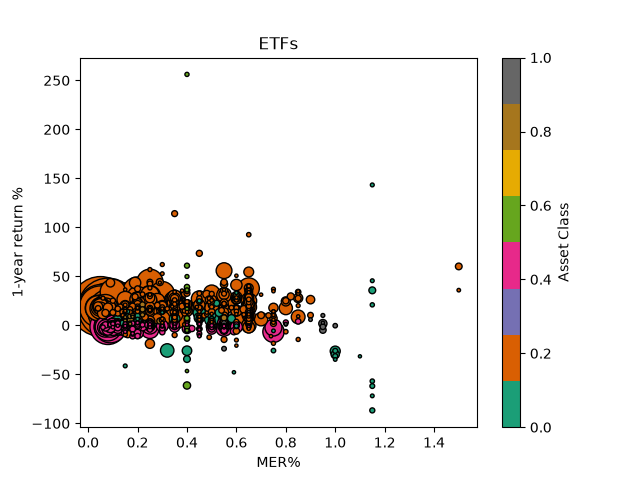

In [270]:
# We leave zero for the remaining, not otherwise specified, values of asset_class
len_asset_class = 5.0
asset_class_colormap_values = {
    'Equity'             : 1/len_asset_class,
    'Fixed Income'       : 2/len_asset_class,
    'Single Stock ETF'   : 3/len_asset_class,
    'Asset Allocation'   : 4/len_asset_class,
    'Alternative'        : 5/len_asset_class
}

# Filter the list of ETFs as desired for plotting.
# Sort from high to low AUM to have small datacircles overlap larger ones.
tmx_etfs_forplot = tmx_etfs.loc[
    (tmx_etfs['aum']>1e8)
    & (tmx_etfs['currency'].isin(['CAD']))
    ].sort_values(by=['aum'], ascending=False)
print(f"Plotting {len(tmx_etfs_forplot)} funds out of {len(tmx_etfs)}.\n")

plt.close('all')
fig, axes = plt.subplots()
artist = axes.scatter(tmx_etfs_forplot['management_fee'], tmx_etfs_forplot['return_1y']*100, 
                      c=tmx_etfs_forplot['asset_class'].map(lambda c : asset_class_colormap_values.get(c, 0)), cmap='Dark2', vmin=0, vmax=1,
                      s=tmx_etfs_forplot['aum']/(2*10**7),
                      edgecolors='black')
fig.colorbar(artist, ax=axes, label='Asset Class')
#axes.set_yscale('log')
axes.set_xlabel('MER%')
#axes.set_xlim(0,(MER_limit*100)*1.1)
axes.set_ylabel('1-year return %')
axes.set_title('ETFs')

# We use the mplcursors module to enable "tooltip" pop-ups when the cursor hovers over a datapoint.
cursor = mplcursors.cursor(axes, hover=True, highlight=True, multiple=False).connect("add", lambda sel: sel.annotation.set_text("\n".join([
    f"{tmx_etfs_forplot.iloc[sel.index,tmx_etfs_forplot.columns.get_loc("symbol")]} {tmx_etfs_forplot.iloc[sel.index,tmx_etfs_forplot.columns.get_loc("name")]}",
    f"AUM: B${tmx_etfs_forplot.iloc[sel.index,tmx_etfs_forplot.columns.get_loc("aum")]/10**9:.1f}"])))

plt.show()

In [220]:
tmx_etfs.iloc[tmx_etfs['inception_date'].idxmax(), [tmx_etfs.columns.get_loc('name'), tmx_etfs.columns.get_loc('inception_date'), tmx_etfs.columns.get_loc('return_1y')]]

name              CI Forge First Conservative Alternative Fund
inception_date                             2026-10-15 00:00:00
return_1y                                                  NaN
Name: 140, dtype: object

In [244]:
1/5.0

0.2

## Mutual Funds

In [27]:
tmx_indices = obb.tmx.index.available(provider='tmx').to_dataframe()
tmx_funds_CA = obb.tmx.equity.search(query='', provider='tmx', country='CA', limit=1e6).to_dataframe()
tmx_funds_US = obb.tmx.equity.search(query='', provider='tmx', country='US', limit=1e6).to_dataframe()
tmx_funds_GB = obb.tmx.equity.search(query='', provider='tmx', country='GB', limit=1e6).to_dataframe()

In [6]:
tmx_indices.info()

<class 'pandas.DataFrame'>
RangeIndex: 145 entries, 0 to 144
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   symbol            145 non-null    str    
 1   name              145 non-null    str    
 2   currency          145 non-null    str    
 3   category          145 non-null    str    
 4   market_value      75 non-null     float64
 5   num_constituents  145 non-null    int64  
 6   overview          145 non-null    str    
 7   methodology       134 non-null    str    
 8   factsheet         88 non-null     str    
dtypes: float64(1), int64(1), str(7)
memory usage: 104.5 KB


In [32]:
tmx_etfs.info()
tmx_etfs.sort_values(by=['aum'],ascending=False).iloc[0:4,[0,12,13]]
tmx_etfs.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 1841 entries, 0 to 1840
Data columns (total 34 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   symbol                 1841 non-null   str    
 1   name                   1841 non-null   str    
 2   short_name             1841 non-null   str    
 3   inception_date         1833 non-null   str    
 4   issuer                 1836 non-null   str    
 5   investment_style       1831 non-null   str    
 6   esg                    1833 non-null   object 
 7   currency               1833 non-null   str    
 8   unit_price             1840 non-null   float64
 9   close                  1840 non-null   float64
 10  prev_close             1840 non-null   float64
 11  avg_volume_30d         1831 non-null   float64
 12  aum                    1840 non-null   float64
 13  management_fee         1805 non-null   float64
 14  asset_class            1836 non-null   str    
 15  region         

,symbol,aum,management_fee
1553,XIC,3.678314e+10,0.0005
1452,VFV,3.677234e+10,0.0008
1755,ZSP,2.603810e+10,0.0008
1523,XEF,2.434960e+10,0.0020


,count,mean,std,min,25%,50%,75%,max
unit_price,1840.0,3.133826e+01,2.565439e+01,1.485000,1.614500e+01,2.390000e+01,3.906750e+01,3.174250e+02
close,1840.0,3.136560e+01,2.566549e+01,1.490000,1.616500e+01,2.393000e+01,3.917000e+01,3.174300e+02
prev_close,1840.0,3.121240e+01,2.557325e+01,1.470000,1.610750e+01,2.380000e+01,3.887500e+01,3.173100e+02
avg_volume_30d,1831.0,1.013908e+05,4.366824e+05,0.000000,1.759000e+03,9.813000e+03,5.194150e+04,1.062395e+07
aum,1840.0,5.549816e+08,2.226096e+09,251900.000000,8.632000e+06,4.749617e+07,2.608626e+08,3.678314e+10
management_fee,1805.0,4.746981e-03,3.017570e-03,0.000400,2.500000e-03,4.000000e-03,6.500000e-03,1.550000e-02
return_1m,1726.0,1.122544e-03,2.214820e-01,-0.763088,-2.801625e-02,-1.066850e-02,5.233250e-03,5.867470e+00
return_3m,1711.0,3.367035e-02,4.085892e-01,-0.784044,-3.081050e-02,-3.347000e-03,2.081850e-02,1.117683e+01
return_6m,1615.0,1.020496e-01,3.068502e-01,-0.818790,-1.553500e-03,6.785000e-02,1.596630e-01,8.618921e+00
return_ytd,1539.0,8.385346e-02,4.844868e-01,-0.901577,-8.141000e-03,5.440000e-02,1.351395e-01,1.715454e+01


Most of the records retrieved as Canadian equities are mutual funds. The number of ETFs is a little larger than from the `obb.tmx.etf` call. Examining the five largest mutual funds, the market cap numbers make sense. However the market caps for the five largest ETFs from `obb.tmx.equity` seem too large. Are these large ETFs the ones missing from the results of `obb.tmx.etf`?

In [50]:
tmx_funds_CA.info()
tmx_funds_CA['security_type'].value_counts()
tmx_funds_CA[tmx_funds_CA['security_type'].isin(['Mutual Fund'])].sort_values(by=['market_cap'],ascending=False).head(5)
tmx_funds_CA[tmx_funds_CA['security_type'].isin(['ETF'])].sort_values(by=['market_cap'],ascending=False).head(5)

<class 'pandas.DataFrame'>
RangeIndex: 101482 entries, 0 to 101481
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   symbol         101482 non-null  str    
 1   name           101482 non-null  str    
 2   exchange       101482 non-null  str    
 3   exchange_code  101482 non-null  str    
 4   country        101482 non-null  str    
 5   security_type  101482 non-null  str    
 6   market_cap     101482 non-null  float64
 7   optionable     101482 non-null  bool   
dtypes: bool(1), float64(1), str(6)
memory usage: 12.0 MB


security_type
Mutual Fund          95417
Equity                3010
ETF                   1873
Future                 454
Money Market Fund      449
Index                  279
Name: count, dtype: int64

,symbol,name,exchange,exchange_code,country,security_type,market_cap,optionable
439,MAW220,Mawer Global Equity Fund Series O,CMF,CMF,CA,Mutual Fund,1.307293e+10,False
459,TDB886,TD Comfort Balanced Portfolio Inv,CMF,CMF,CA,Mutual Fund,1.112173e+10,False
473,TDB887,TD Comfort Balanced Growth Portfolio Inv,CMF,CMF,CA,Mutual Fund,1.024489e+10,False
483,MAW202,Mawer International Equity Fund Series O,CMF,CMF,CA,Mutual Fund,9.623085e+09,False
494,BMO146,BMO Dividend Fund Series A,CMF,CMF,CA,Mutual Fund,8.902902e+09,False


,symbol,name,exchange,exchange_code,country,security_type,market_cap,optionable
33,LRCX,Lam Research CDR (CAD Hedged),TSX,TSX,CA,ETF,4.934937e+11,False
43,SAPS,SAP CDR (CAD Hedged),TSX,TSX,CA,ETF,3.928581e+11,False
56,KLAC,KLA CDR (CAD Hedged),TSX,TSX,CA,ETF,3.235826e+11,False
59,MRV,Marvell Technology CDR (CAD Hedged),TSX,TSX,CA,ETF,3.006602e+11,False
62,SNDK,Sandisk CDR (CAD Hedged),TSX,TSX,CA,ETF,2.881020e+11,False


Country codes `US` and `GB` give results that look misplaced, these are not lists of equities.

In [25]:
tmx_funds_US
tmx_funds_GB.info()
tmx_funds_GB['security_type'].value_counts()
tmx_funds_GB.sort_values(by=['market_cap'],ascending=False).head(5)

,symbol,name,exchange,exchange_code,country,security_type,market_cap,optionable
0,^OMXSPI,OMX Stockholm_PI,NSD,GIDS,US,Index,0.0,False
1,^OMXC20,OMX Copenhagen 20,NSD,GIDS,US,Index,0.0,False
2,^OMXS30,OMX Stockholm 30 Index,NSD,GIDS,US,Index,0.0,False
3,^OMXH25,OMX Helsinki 25,NSD,GIDS,US,Index,0.0,False


<class 'pandas.DataFrame'>
RangeIndex: 13752 entries, 0 to 13751
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   symbol         13752 non-null  str    
 1   name           13752 non-null  str    
 2   exchange       13752 non-null  str    
 3   exchange_code  13752 non-null  str    
 4   country        13752 non-null  str    
 5   security_type  13752 non-null  str    
 6   market_cap     13752 non-null  float64
 7   optionable     13752 non-null  bool   
dtypes: bool(1), float64(1), str(6)
memory usage: 1.3 MB


security_type
Forex    13752
Name: count, dtype: int64

,symbol,name,exchange,exchange_code,country,security_type,market_cap,optionable
0,$DKKPLN,Denmark Kroner - Poland Zlotych,FOREX,FRXL,GB,Forex,0.0,False
9159,$DKKXMR,Denmark Kroner - Monero,FOREX,FRXL,GB,Forex,0.0,False
9161,$FEDFUN,FED - FUN,FOREX,FRXL,GB,Forex,0.0,False
9162,$DJFXBH,Djibouti Francs - Bitcoin Cash,FOREX,FRXL,GB,Forex,0.0,False
9163,$DKKNZD,Denmark Kroner - New Zealand Dollars,FOREX,FRXL,GB,Forex,0.0,False


Let's concentrate on the Canadian ETFs and mutual funds. Which ETFs are found only in the `obb.tmx.equity` result? There are two groups: Canadian Depository Receipts, and a few ETFs whose market cap is reported as zero. To compare these to the ETFs from the `obb.tmx.etf` call, we would need to retrieve further information about them.

In [36]:
tmx_funds_CA[(tmx_funds_CA['security_type'].isin(['ETF'])) & (~(tmx_funds_CA['symbol'].isin(tmx_etfs['symbol'])))]

,symbol,name,exchange,exchange_code,country,security_type,market_cap,optionable
33,LRCX,Lam Research CDR (CAD Hedged),TSX,TSX,CA,ETF,4.934937e+11,False
43,SAPS,SAP CDR (CAD Hedged),TSX,TSX,CA,ETF,3.928581e+11,False
56,KLAC,KLA CDR (CAD Hedged),TSX,TSX,CA,ETF,3.235826e+11,False
59,MRV,Marvell Technology CDR (CAD Hedged),TSX,TSX,CA,ETF,3.006602e+11,False
62,SNDK,Sandisk CDR (CAD Hedged),TSX,TSX,CA,ETF,2.881020e+11,False
64,TTES,TotalEnergies CDR (CAD Hedged),TSX,TSX,CA,ETF,2.785918e+11,False
77,NOVO,Novo Nordisk CDR (CAD Hedged),TSX,TSX,CA,ETF,2.468226e+11,False
81,SCHN,Schneider Electric CDR (CAD Hedged),TSX,TSX,CA,ETF,2.419645e+11,False
82,TMUS,T-Mobile CDR (CAD Hedged),TSX,TSX,CA,ETF,2.394010e+11,False
91,UBSS,UBS CDR (CAD Hedged),TSX,TSX,CA,ETF,2.107490e+11,False


There are additional ways to access data, besides a search. An equity `screener` does not provide any additional info about mutual funds that were not present in the `search`. We also try `profile`.

In [162]:
tmx_funds_screener1 = obb.tmx.equity.screener(exchange='CMF', symbol_type='Mutual Fund', market_cap_min=1e9, limit=1e6, provider='tmx').to_dataframe()
tmx_funds_screener1.info()
display(tmx_funds_screener1)

<class 'pandas.DataFrame'>
RangeIndex: 310 entries, 0 to 309
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   symbol        310 non-null    str    
 1   name          310 non-null    str    
 2   exchange      310 non-null    str    
 3   country       310 non-null    str    
 4   symbol_type   310 non-null    str    
 5   optionable    310 non-null    bool   
 6   market_cap    310 non-null    float64
 7   symbolId      310 non-null    int64  
 8   aliases       310 non-null    object 
 9   exchangeCode  310 non-null    str    
dtypes: bool(1), float64(1), int64(1), object(1), str(6)
memory usage: 41.9+ KB


,symbol,name,exchange,country,symbol_type,optionable,market_cap,symbolId,aliases,exchangeCode
0,MAW220,Mawer Global Equity Fund Series O,CMF,CA,Mutual Fund,False,1.292483e+10,68752668,[],CMF
1,TDB886,TD Comfort Balanced Portfolio Inv,CMF,CA,Mutual Fund,False,1.108084e+10,49563352,[],CMF
2,TDB887,TD Comfort Balanced Growth Portfolio Inv,CMF,CA,Mutual Fund,False,1.020116e+10,49563353,[],CMF
3,MAW202,Mawer International Equity Fund Series O,CMF,CA,Mutual Fund,False,9.487549e+09,68752661,[],CMF
4,BMO70146,BMO Dividend Fund Series A,CMF,CA,Mutual Fund,False,8.997636e+09,61919583,[],CMF
...,...,...,...,...,...,...,...,...,...,...
305,CIG14020,CI Cambridge Canadian Equity Corporate Class A,CMF,CA,Mutual Fund,False,1.003995e+09,49157305,[],CMF
306,CIG14220,CI Canadian Equity Corporate Class A,CMF,CA,Mutual Fund,False,1.003995e+09,48934752,[],CMF
307,CIG14120,CI Canadian Equity Corporate Class A,CMF,CA,Mutual Fund,False,1.003995e+09,48934750,[],CMF
308,CIG11330,CI Canadian Equity Corporate Class A,CMF,CA,Mutual Fund,False,1.003995e+09,93715338,[],CMF


Note that Series O mutual funds are not available to retail investors, and Series F have an up-front fee. We ignore these funds in our analysis, focusing on Series A and AH.

In [74]:
tmx_funds_profile1 = obb.tmx.equity.profile(symbol='TDB886', provider='tmx').to_dataframe()
display(tmx_funds_profile1)
tmx_funds_quote1 = obb.tmx.equity.quote(symbol='TDB886', provider='tmx').to_dataframe()
display(tmx_funds_quote1.T)
tmx_funds_CA[(tmx_funds_CA['security_type'].isin(['Mutual Fund'])) & (tmx_funds_CA['market_cap']>1e8)].sort_values(by=['market_cap'],ascending=False)

,symbol,name,stock_exchange,long_description,company_url,business_address,business_phone_no,email,share_outstanding,total_shares_outstanding
0,TDB886,TD Comfort Balanced Portfolio Inv,CMF,The fundamental investment objective is to see...,https://www.tdam.com,"P.O. Box 100, 66 Wellington Street West, Toron...",800-588-8054,info@tdqc.com,0,0


,0
symbol,TDB886
name,TD Comfort Balanced Portfolio Inv
exchange,CMF
last_price,21.68
prev_close,21.77
change,-0.09
change_percent,-0.004134
year_high,22.044434
year_low,20.326199
security_type,mutual fund


,symbol,name,exchange,exchange_code,country,security_type,market_cap,optionable
439,MAW220,Mawer Global Equity Fund Series O,CMF,CMF,CA,Mutual Fund,1.307293e+10,False
459,TDB886,TD Comfort Balanced Portfolio Inv,CMF,CMF,CA,Mutual Fund,1.112173e+10,False
473,TDB887,TD Comfort Balanced Growth Portfolio Inv,CMF,CMF,CA,Mutual Fund,1.024489e+10,False
483,MAW202,Mawer International Equity Fund Series O,CMF,CMF,CA,Mutual Fund,9.623085e+09,False
494,BMO146,BMO Dividend Fund Series A,CMF,CMF,CA,Mutual Fund,8.902902e+09,False
...,...,...,...,...,...,...,...,...
4218,FRC759,Russell Investments Focused US Equity Pool O,CMF,CMF,CA,Mutual Fund,1.001893e+08,False
4219,INA38402,iA Diversified Opportunity SRP75100Pr,CMF,CMF,CA,Mutual Fund,1.000312e+08,False
4220,INA38404,iA Diversified Opportunity SRP75100Pr,CMF,CMF,CA,Mutual Fund,1.000312e+08,False
4221,INA38406,iA Diversified Opportunity SRP75100Pr,CMF,CMF,CA,Mutual Fund,1.000312e+08,False


Try to find other ways of getting info about a fund.

In [152]:
tmx_funds_screener2 = obb.tmx.equity.screener(exchange='CMF', symbol_type='Mutual Fund', market_cap_min=1e10, provider='tmx')

In [153]:
tmx_funds_screener2.json()

C:\Users\Sara\AppData\Local\Temp\ipykernel_25320\3928186500.py:1: PydanticDeprecatedSince20: The `json` method is deprecated; use `model_dump_json` instead. Deprecated in Pydantic V2.0 to be removed in V3.0. See Pydantic V2 Migration Guide at https://errors.pydantic.dev/2.14/migration/
  tmx_funds_screener2.json()


'{"id":"06ad90d7-b87a-7b81-8000-b3b3f4dbeae3","results":[{"symbol":"MAW220","name":"Mawer Global Equity Fund Series O","exchange":"CMF","country":"CA","symbol_type":"Mutual Fund","expiration":null,"currency":null,"sector":null,"primary_symbol":null,"filing_current":null,"optionable":false,"market_cap":12924827389.0,"intraday_market_cap":null,"price":null,"settlement_price":null,"intraday_price":null,"open":null,"high":null,"low":null,"prev_close":null,"price_change":null,"net_change":null,"high_52w":null,"low_52w":null,"above_52w_high":null,"below_52w_low":null,"change_52w":null,"performance_7d":null,"performance_30d":null,"performance_90d":null,"performance_ytd":null,"volume":null,"open_interest":null,"transactions":null,"volume_previous_day":null,"volume_avg_10d":null,"volume_avg_30d":null,"volume_avg_50d":null,"volume_avg_90d":null,"trade_value_avg_90d":null,"beta":null,"alpha":null,"r_squared":null,"standard_deviation":null,"insider_holdings":null,"institutional_holdings":null,"pe_

The openBB `tmx` provider does not have MERs for mutual funds.

We try another package, `mstarpy`. To understand how to use it, in addition to reading the docs, we also make use of IPython's tab completion and introspection. Unfortunately, this package also fails to retrieve the MER of mutual funds, even though the data is available on `global.morningstar.com`. Is it possible that the filters still work on fields, even if those fields are not in the results? No, experiments setting a filter for `marketCap` greater than `1e20` show this is not the case.

Maybe we need to ask for the MER one fund at a time, rather than with the search facility? Yes, this works, although the data is not always in the same place.

In [88]:
mstar_session = mstarpy.MorningstarSession()

In [95]:
mstar_possible_search_fields = mstar_session.search_field()

⚠️ WAF challenge detected → refreshing cookies
possible fields for screener can be : abiSector, accumulationNisa, actualDeferredLoad, actualFrontLoad, aimcCategory, alpha, annualReportOngoingCharge, averageManagerTenure, baseCurrency, beta, brandingName, broadCategoryGroup, corporateSustainabilityScore, countriesOfSale, currency, debtToEquity, dgsCode, distributionFundType, distributionYield, dividendDistributionFrequency, dividendYield, domicile, earningsGrowthPerShare, exchange, exchangeCountry, firmName, freeCashFlow, freeCashFlowYield, fundAlternativeStyleBox, fundEquityStyleBox, fundFixedIncomeStyleBox, fundServCodes, fundSize, fundSizeDate, fundStarRating, gearingRatio, hasPerformanceFee, hasPPM, iaSector, identifier, inceptionDate, industry, investmentType, isin, isIndexFund, isJapaneseDefinedContribution, isJapanesePublicFund, isJapaneseSMA, isNisaEligible, isTisaEligible, itaCode, japanAfterTaxTotalExpenseRatio, japanGrowthNisa, lastPrice, lastPriceDate, managementExpenseRatio

In [101]:
mstar_possible_filters = mstar_session.search_filter("type")
mstar_possible_filters

['investmentType', 'countriesOfSale']

In [158]:
mstar_screener_filter = {"baseCurrency" : "CAD",
                         "fundSize" : (">", 1e20)}
mstar_screen_data = mstar_session.screener_universe(term='TD', language='en-ca',
                                                    field=["ticker", "name", "managementExpenseRatio", "managementFee", "maximumManagementFee", "marketCap", "baseCurrency",
                                                           "exchange","domicile","exchangeCountry",
                                                           "fundAlternativeStyleBox", "fundEquityStyleBox", "fundFixedIncomeStyleBox"], 
                                                    filters=mstar_screener_filter,
                                                    pageSize=20, page=1, sortby="ticker", ascending=True)

In [160]:
len(mstar_screen_data)

20

In [122]:
mstar_fund = mstarpy.Funds('TDB886')

Based on the documentation, we expect to find the MER information in one of three places. However this might vary by fund. We create a little function that returns the MER of a fund.

In [185]:
mer_list = [mstar_fund.feeLevel().get('prospectusExpenseRatio'),
            mstar_fund.feeLevel().get('adjustedProspectusExpenseRatio'),
            mstar_fund.costIllustration().get('mer')]
mer_max = max([mer for mer in mer_list if mer is not None])
type(mer_max)

float

In [200]:
def mstar_fund_mer(fund_name:str) -> float:
    # Get the MER of a mutual fund by looking in some likely locations.
    # Return None if we cannot find the mutual fund.
    try:
        fund = mstarpy.Funds(fund_name)
        mer_list = [fund.feeLevel().get('prospectusExpenseRatio'),
                fund.feeLevel().get('adjustedProspectusExpenseRatio'),
                fund.costIllustration().get('mer')]
        mer_max = max([mer for mer in mer_list if mer is not None])
    except ValueError:
        mer_max = None
    return mer_max

In [197]:
fund_mer = mstar_fund_mer('BMO146')

In [199]:
display(fund_mer)

None